# Telco Customer Churn: Exploratory Analysis and Prediction

**Project purpose:** analyze customer and service information, then build a model that estimates whether a customer is likely to leave the telecom provider.

**Defense roadmap:** explain the data → prepare reliable features → train and compare classifiers → evaluate churn detection → tune and track a model → expose predictions through a Streamlit interface.

**Key presentation point:** this is a decision-support prototype. A churn probability is an estimate, not a guarantee that an individual customer will leave.

## About the Dataset

The project uses the Telco Customer Churn dataset. Each row represents one customer; columns describe demographics, subscribed services, account details, charges, and whether the customer left during the recorded period.

### Why this problem matters

The business goal is to identify customers who may be at risk so a retention team can investigate appropriate support or offers. Predictions should support, not replace, human decisions.

### Main feature groups

- **Demographics:** gender, senior-citizen status, partner, and dependents.
- **Services:** phone, internet, security, backup, device protection, support, and streaming.
- **Account:** tenure, contract, billing preference, payment method, and charges.
- **Target:** `Churn` indicates whether the customer left. It is excluded from model inputs to prevent the model from seeing the answer.

## 1. Exploration and Data Loading

First load the analysis libraries and read the CSV file. The path check supports running the notebook either from the project directory or its parent. The initial preview and record count help confirm that the expected file was loaded.

In [36]:
import pandas as pd
import numpy as np
from joblib import dump
import os
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import  RandomForestClassifier,VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import  matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score
from sklearn.metrics import classification_report, roc_auc_score

In [37]:
from pathlib import Path

csv_path = Path.cwd() / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not csv_path.exists():
    csv_path = Path.cwd().parent / csv_path.name

if not csv_path.exists():
    raise FileNotFoundError(f"Could not find the churn dataset: {csv_path}")

data = pd.read_csv(csv_path)
print(f"Loaded {len(data)} customer records from {csv_path}")
print(data.head())

Loaded 7043 customer records from c:\Users\OLAGOKE O\Desktop\chun project\WA_Fn-UseC_-Telco-Customer-Churn.csv
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fibe

## 2. Data Quality, Target, and Train/Test Split

Check missing values and column types before modeling. `TotalCharges` can contain blank strings, so it is converted to numeric with invalid entries treated as missing, then those missing values are filled with the median.

`customerID` is an identifier rather than a useful behavioral feature, so it is removed. `Churn` becomes a binary target (`Yes` → 1, `No` → 0). A stratified 80/20 split keeps the churn proportion similar in both sets and reserves test data for evaluation. The correlation output is a quick numeric-feature diagnostic, not proof of causation.

In [17]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [18]:
print(data['Churn'].dtype)

str


In [38]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors='coerce')
data["TotalCharges"].isnull().sum()
data['TotalCharges'] = data['TotalCharges'].fillna(data['TotalCharges'].median())
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [39]:
X=data.drop(['customerID', 'Churn'], axis=1)
y=data['Churn'].apply(lambda x:1 if x=="Yes" else 0)
data_temp = data.copy()
data_temp['Churn_numeric'] = y

# Compute correlations
corr_matrix = data_temp.corr(numeric_only=True)

# Get correlations with y
churn_corr = corr_matrix['Churn_numeric'].sort_values(ascending=False)
print(churn_corr)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
num_col=X.select_dtypes(include=np.number).columns
cat_col=X.select_dtypes(exclude=np.number).columns
X.info()

y.info()

Churn_numeric     1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.199037
tenure           -0.352229
Name: Churn_numeric, dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 

In [21]:
X.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

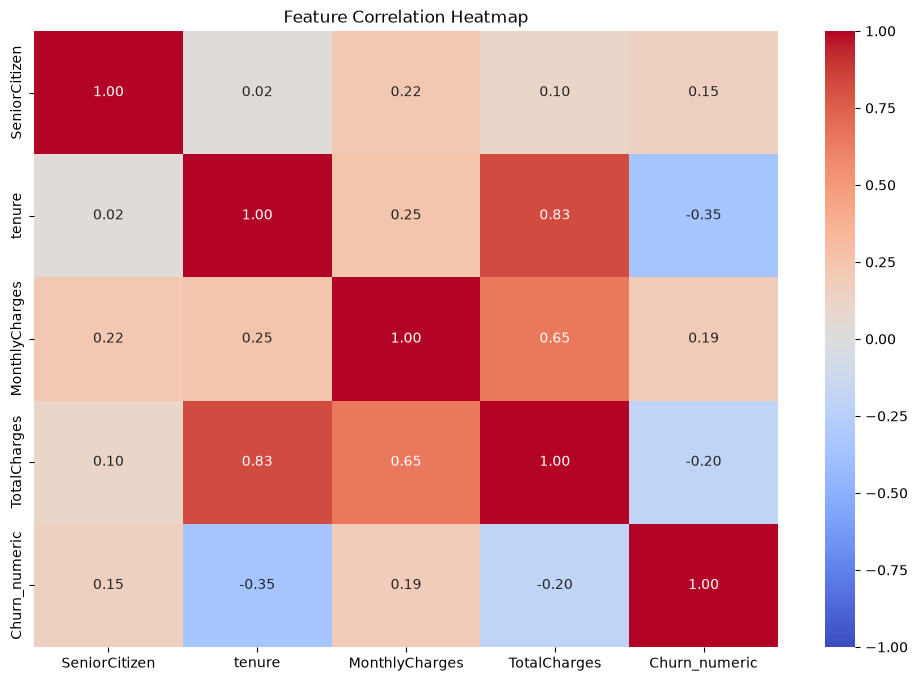

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix.fillna(0),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1
)
plt.title("Feature Correlation Heatmap")
plt.show()

## 3. Feature Preparation and Preprocessing Pipeline

Numeric columns are median-imputed and standardized; categorical columns are imputed with their most frequent value and one-hot encoded. A `ColumnTransformer` applies the appropriate processing to each column group, and the model `Pipeline` keeps preprocessing attached to the classifier.

This is important for deployment: the same transformations learned from training data are applied to new customer records. One-hot encoding also uses `handle_unknown='ignore'` so an unseen category does not immediately break inference.

In [40]:
num_col=X.select_dtypes(include=np.number).columns
cat_col=X.select_dtypes(exclude=np.number).columns
num_pipeline=Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                             ('enoder', OneHotEncoder(handle_unknown='ignore'))])

In [24]:

cat_col.isnull().sum()

np.int64(0)

## 4. Model Training: Soft-Voting Ensemble

The ensemble combines Logistic Regression, Random Forest, LightGBM, and XGBoost. These models capture different patterns: a linear baseline, tree-based interactions, and boosted decision trees. `VotingClassifier(voting='soft')` averages class probabilities, with larger weights assigned to LightGBM and XGBoost.

Class balancing is used for several learners because churn datasets often have fewer churners than non-churners. The preprocessing and classifier are fit together using the training split; the test split is kept separate for later evaluation.

In [41]:
rf=RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced',n_jobs=-1)
lr=LogisticRegression(max_iter=1000, random_state=42,class_weight='balanced',n_jobs=-1)
lg=LGBMClassifier(n_estimators=100, random_state=42,class_weight='balanced',n_jobs=-1,learning_rate=0.05)
xg=XGBClassifier( n_estimators=100,
    random_state=42,
    n_jobs=-1,
    learning_rate=0.05,
    max_depth=6,
    eval_metric='logloss')
Voting=VotingClassifier(estimators=[('rf',rf),('lr',lr),('xl',lg),('xg',xg)],voting='soft',n_jobs=-1,weights=[1,1,2,3],)
processor=ColumnTransformer(transformers=[('num',num_pipeline,num_col),
                                          ('cat',cat_pipeline,cat_col)])
model=Pipeline(steps=[('preprocessor',processor),('classifier',Voting)])
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

## 5. Evaluation and Threshold Selection

The evaluation reports precision, recall, F1, and ROC-AUC. Precision answers “Of the customers flagged, how many churned?”; recall answers “Of the churners, how many did we find?”; F1 balances precision and recall; ROC-AUC measures ranking across probability thresholds.

The threshold of 0.30 is lower than the default 0.50, making the classifier more willing to flag possible churners. This may improve churn recall but can also increase false alarms. The threshold table illustrates this trade-off; the business should choose it based on the relative cost of missed churn and unnecessary retention outreach.

In [26]:
TRESHOLD= 0.3
xtest=model.named_steps['preprocessor'].transform(X_test)
for name, estimator in model.named_steps['classifier'].named_estimators_.items():
    y_pred = estimator.predict_proba(xtest)[:, 1]
    y_pred = (y_pred >= TRESHOLD).astype(int)
    print(f"Model: {name}")
    print(classification_report(y_test, y_pred,labels=[0,1]))
    print(f"ROC AUC Score: {roc_auc_score(y_test, estimator.predict_proba(xtest)[:, 1])}\n")

Model: rf
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1035
           1       0.46      0.84      0.60       374

    accuracy                           0.70      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.70      0.72      1409

ROC AUC Score: 0.8208142809165827

Model: lr
              precision    recall  f1-score   support

           0       0.95      0.55      0.70      1035
           1       0.43      0.93      0.59       374

    accuracy                           0.65      1409
   macro avg       0.69      0.74      0.64      1409
weighted avg       0.82      0.65      0.67      1409

ROC AUC Score: 0.8412978893797307

Model: xl
              precision    recall  f1-score   support

           0       0.94      0.61      0.74      1035
           1       0.45      0.89      0.60       374

    accuracy                           0.69      1409
   macro avg       0.70     

In [27]:
xtest=model.named_steps['preprocessor'].transform(X_test)

for name, estimator in model.named_steps['classifier'].named_estimators_.items():
    y_pred = estimator.predict(xtest)
    print(f"Model: {name}")
    print(classification_report(y_test, y_pred))
    print(f"ROC AUC Score: {roc_auc_score(y_test, estimator.predict_proba(xtest)[:, 1])}\n")

Model: rf
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



ROC AUC Score: 0.8208142809165827

Model: lr
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC AUC Score: 0.8412978893797307

Model: xl
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409

ROC AUC Score: 0.8417008964323541

Model: xg
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.64      0.52      0.57       374

    accuracy                           0.79    

In [42]:
TRESHOLD= 0.3
proba=model.predict_proba(X_test)[:,1]
y_pred=(proba>=TRESHOLD).astype(int)

print(classification_report(y_test, y_pred, labels=[0,1]))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC Score:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.92      0.67      0.78      1035
           1       0.48      0.85      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.81      0.72      0.73      1409

Accuracy: 0.7154009936124911
AUC Score: 0.8440595210416183


In [29]:
print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred_thresh = (proba >= thresh).astype(int)
    precision_1 = precision_score(y_test, y_pred_thresh, pos_label=1)
    recall_1 = recall_score(y_test, y_pred_thresh, pos_label=1)
    f1_1 = f1_score(y_test, y_pred_thresh, pos_label=1)
    print(f"{thresh:<8.3f}{precision_1:<8.3f}{recall_1:<8.3f}{f1_1:<8.3f}")


Thresh  Prec_1  Rec_1   F1_1    
0.250   0.459   0.888   0.605   
0.300   0.480   0.848   0.613   
0.350   0.512   0.816   0.629   
0.400   0.525   0.773   0.625   
0.450   0.551   0.727   0.627   
0.500   0.566   0.658   0.608   


## 6. Hyperparameter Tuning and Experiment Tracking (Optuna + MLflow)

Optuna searches selected Random Forest, LightGBM, and XGBoost parameters across 20 trials, maximizing ROC-AUC. The selected parameters are used to fit a final soft-voting model, and MLflow records parameters, training time, evaluation metrics, and the model artifact for reproducibility.

> **Defense caveat / recommended improvement:** the current Optuna objective evaluates every trial on `X_test` and `y_test`. This leaks test-set feedback into model selection, so the final test score may be optimistic. For a stronger final experiment, tune using a validation split or cross-validation within the training data, then evaluate the selected model on the test set only once.

In [49]:
%pip install -q mlflow optuna

import os
import time
import mlflow
import mlflow.sklearn
import optuna
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, classification_report

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
project_root = os.path.abspath(os.getcwd()).replace("\\", "/")
mlruns_path = f"file:///{project_root}/mlruns"
mlflow.set_tracking_uri(mlruns_path)
mlflow.set_experiment(experiment_name="Telco Churn - VotingClassifier Optuna")

Xt_train = model.named_steps['preprocessor'].transform(X_train)
Xt_test = model.named_steps['preprocessor'].transform(X_test)

def objective(trial):
    rf = RandomForestClassifier(
        n_estimators=trial.suggest_int("rf_n_estimators", 50, 200),
        max_depth=trial.suggest_int("rf_max_depth", 3, 10),
        random_state=42,
        class_weight='balanced',
        n_jobs=-1,
    )
    lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced', n_jobs=-1)
    lg = LGBMClassifier(
        n_estimators=trial.suggest_int("lg_n_estimators", 50, 200),
        learning_rate=trial.suggest_float("lg_learning_rate", 0.01, 0.1),
        random_state=42,
        class_weight='balanced',
        n_jobs=-1,
    )
    xg = XGBClassifier(
        n_estimators=trial.suggest_int("xg_n_estimators", 50, 200),
        learning_rate=trial.suggest_float("xg_learning_rate", 0.01, 0.1),
        max_depth=trial.suggest_int("xg_max_depth", 3, 10),
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',
    )
    voting_trial = VotingClassifier(
        estimators=[('rf', rf), ('lr', lr), ('lg', lg), ('xg', xg)],
        voting='soft',
        n_jobs=-1,
        weights=[1, 1, 2, 3],
    )
    voting_trial.fit(Xt_train, y_train)
    probabilities = voting_trial.predict_proba(Xt_test)[:, 1]
    return roc_auc_score(y_test, probabilities)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)
print("Best AUC:", study.best_value)
print("Best params:", study.best_params)

best_params = study.best_params
rf_best = RandomForestClassifier(
    n_estimators=best_params["rf_n_estimators"],
    max_depth=best_params["rf_max_depth"],
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
)
lr_best = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced', n_jobs=-1)
lg_best = LGBMClassifier(
    n_estimators=best_params["lg_n_estimators"],
    learning_rate=best_params["lg_learning_rate"],
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
)
xg_best = XGBClassifier(
    n_estimators=best_params["xg_n_estimators"],
    learning_rate=best_params["xg_learning_rate"],
    max_depth=best_params["xg_max_depth"],
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
)

voting_best = VotingClassifier(
    estimators=[('rf', rf_best), ('lr', lr_best), ('lg', lg_best), ('xg', xg_best)],
    voting='soft',
    n_jobs=-1,
    weights=[1, 1, 2, 3],
)

threshold = 0.3
with mlflow.start_run(run_name="VotingPipeline_Preprocessed"):
    mlflow.log_params(best_params)
    mlflow.log_param("threshold", threshold)

    start_train = time.time()
    voting_best.fit(Xt_train, y_train)
    mlflow.log_metric("train_time", time.time() - start_train)

    probabilities = voting_best.predict_proba(Xt_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    roc_auc = roc_auc_score(y_test, probabilities)
    mlflow.log_metrics({
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
    })

    trusted_types = [
        "collections.OrderedDict",
        "lightgbm.basic.Booster",
        "lightgbm.sklearn.LGBMClassifier",
        "sklearn.tree._tree.Tree",
        "sklearn.utils._bunch.Bunch",
        "xgboost.core.Booster",
        "xgboost.sklearn.XGBClassifier",
    ]
    mlflow.sklearn.log_model(
        voting_best,
        artifact_path="voting_model",
        skops_trusted_types=trusted_types,
    )

    print("\n===== Classification Report =====")
    print(classification_report(y_test, predictions))
    print(f"ROC AUC: {roc_auc:.4f}")


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


[I 2026-10-11 00:28:02,538] A new study created in memory with name: no-name-9b52bdae-6500-428c-9289-77be6285fe55
[I 2026-10-11 00:28:04,289] Trial 0 finished with value: 0.8384845901469942 and parameters: {'rf_n_estimators': 118, 'rf_max_depth': 10, 'lg_n_estimators': 65, 'lg_learning_rate': 0.045573231418867245, 'xg_n_estimators': 191, 'xg_learning_rate': 0.0878786695089357, 'xg_max_depth': 10}. Best is trial 0 with value: 0.8384845901469942.
[I 2026-10-11 00:28:05,328] Trial 1 finished with value: 0.8443126921387791 and parameters: {'rf_n_estimators': 55, 'rf_max_depth': 10, 'lg_n_estimators': 104, 'lg_learning_rate': 0.05649819943121714, 'xg_n_estimators': 75, 'xg_learning_rate': 0.08749587141200776, 'xg_max_depth': 5}. Best is trial 1 with value: 0.8443126921387791.
[I 2026-10-11 00:28:06,613] Trial 2 finished with value: 0.8422382391691854 and parameters: {'rf_n_estimators': 96, 'rf_max_depth': 9, 'lg_n_estimators': 93, 'lg_learning_rate': 0.08633223140522935, 'xg_n_estimators': 

Best AUC: 0.8462734764525045
Best params: {'rf_n_estimators': 136, 'rf_max_depth': 8, 'lg_n_estimators': 81, 'lg_learning_rate': 0.04349829116867538, 'xg_n_estimators': 100, 'xg_learning_rate': 0.06298926277929714, 'xg_max_depth': 4}


2026/10/11 00:28:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



===== Classification Report =====
              precision    recall  f1-score   support

           0       0.93      0.65      0.77      1035
           1       0.47      0.87      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.81      0.71      0.72      1409

ROC AUC: 0.8463


## 7. Feature Importance

The chart ranks transformed input features by importance from the LightGBM member of the ensemble. It can help explain which attributes influenced that model’s predictions most, but importance is not a causal effect and should not be presented as proof that a feature causes churn. Correlated features can share or distort importance.

                                    Feature  Importance
2                            MonthlyCharges         684
3                              TotalCharges         626
1                                    tenure         498
43           PaymentMethod_Electronic check         103
39                      PaperlessBilling_No          79
4                             gender_Female          67
27                           TechSupport_No          64
21                          OnlineBackup_No          64
18                        OnlineSecurity_No          63
12                         MultipleLines_No          57
36                  Contract_Month-to-month          56
0                             SeniorCitizen          51
37                        Contract_One year          50
41  PaymentMethod_Bank transfer (automatic)          48
8                             Dependents_No          42
33                       StreamingMovies_No          41
38                        Contract_Two year     

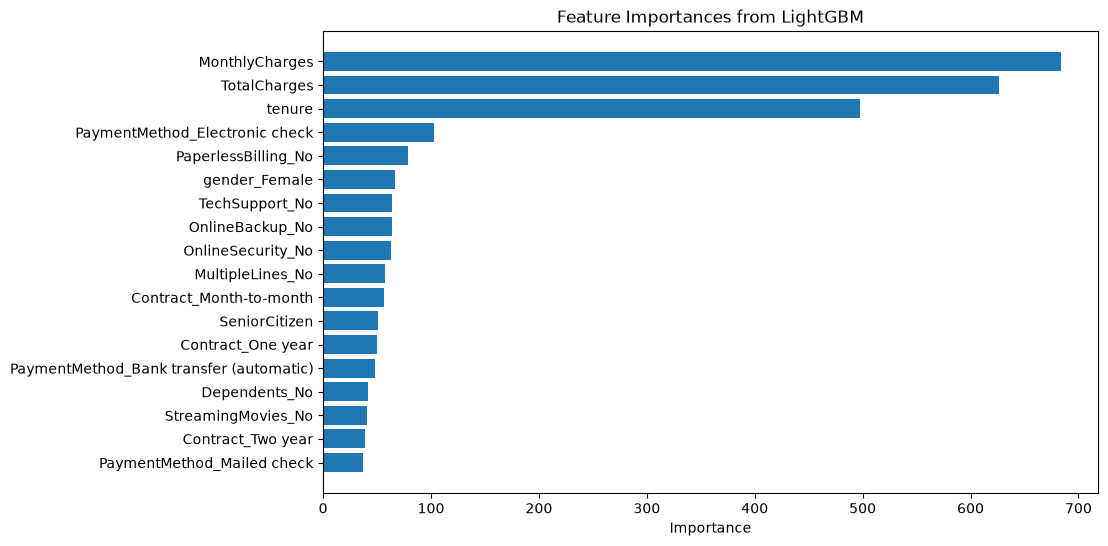

In [46]:
num_feature=num_col
cat_features=model.named_steps['preprocessor'].transformers_[1][1] \
      .named_steps['enoder'].get_feature_names_out(cat_col)
feature=np.concatenate([num_feature,cat_features])
importances=model.named_steps['classifier'].named_estimators_['xl'].feature_importances_
feature_importances=pd.DataFrame({'Feature':feature,'Importance':importances}).sort_values(by='Importance',ascending=False)
print(feature_importances.head(20))
plt.figure(figsize=(10,6))
plt.barh(feature_importances['Feature'].head(20)[:-2], feature_importances['Importance'].head(20)[:-2])
plt.xlabel('Importance')
plt.title('Feature Importances from LightGBM')
plt.gca().invert_yaxis()
plt.show()

## 8. Save the Trained Model

Create an `artifacts` folder if needed and serialize the fitted preprocessing-and-classifier pipeline with Joblib. Saving the complete pipeline ensures the app can apply the same transformations at prediction time. Keep the model file and the app in the expected project paths.

In [43]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path.cwd() / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, ARTIFACTS_DIR / "churn_model1.pkl")
print(f"Saved model to {ARTIFACTS_DIR / 'churn_model1.pkl'}")

Saved model to c:\Users\OLAGOKE O\Desktop\chun project\artifacts\churn_model1.pkl


## 9. Streamlit Setup

Install Streamlit in the notebook environment before generating and launching the app. In a defense, mention that the notebook creates `app.py` as a separate user interface script, while the fitted model is loaded from the saved artifact.

In [44]:
%pip install -q streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 10. Streamlit App: Input Form and Prediction

This cell writes `app.py`. The app loads the saved model once with Streamlit caching, collects the same customer features used during training, builds a one-row DataFrame, and displays the estimated churn probability. A sidebar threshold controls how that probability is converted into a “likely to churn” or “likely to stay” message.

The input column names and category values must match the training data. Error handling provides a visible message if model loading or prediction fails.

In [45]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

model_path = Path(__file__).parent / "artifacts" / "churn_model1.pkl"

@st.cache_resource
def load_model():
    return joblib.load(model_path)

try:
    model = load_model()
    st.success("Model loaded successfully!")
except Exception as e:
    st.error(f"Error loading model: {e}")
    st.stop()

st.title("Customer Churn Prediction App")
st.write("Enter customer details below to predict the likelihood of churning.")

col1, col2 = st.columns(2)

with col1:
    gender = st.selectbox("Gender", ["Female", "Male"])
    SeniorCitizen = st.selectbox("Senior Citizen (0=No, 1=Yes)", [0, 1])
    Partner = st.selectbox("Partner", ["Yes", "No"])
    Dependents = st.selectbox("Dependents", ["Yes", "No"])
    tenure = st.slider("Tenure (Months)", 0, 72, 12)
    PhoneService = st.selectbox("Phone Service", ["Yes", "No"])
    MultipleLines = st.selectbox("Multiple Lines", ["No phone service", "No", "Yes"])
    InternetService = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
    OnlineSecurity = st.selectbox("Online Security", ["No", "Yes", "No internet service"])

with col2:
    OnlineBackup = st.selectbox("Online Backup", ["No", "Yes", "No internet service"])
    DeviceProtection = st.selectbox("Device Protection", ["No", "Yes", "No internet service"])
    TechSupport = st.selectbox("Tech Support", ["No", "Yes", "No internet service"])
    StreamingTV = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
    StreamingMovies = st.selectbox("Streaming Movies", ["No", "Yes", "No internet service"])
    Contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    PaperlessBilling = st.selectbox("Paperless Billing", ["Yes", "No"])
    PaymentMethod = st.selectbox("Payment Method", [
        "Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"
    ])
    MonthlyCharges = st.number_input("Monthly Charges ($)", min_value=0.0, max_value=200.0, value=50.0)
    TotalCharges = st.number_input("Total Charges ($)", min_value=0.0, max_value=10000.0, value=600.0)

input_data = {
    "gender": gender,
    "SeniorCitizen": SeniorCitizen,
    "Partner": Partner,
    "Dependents": Dependents,
    "tenure": tenure,
    "PhoneService": PhoneService,
    "MultipleLines": MultipleLines,
    "InternetService": InternetService,
    "OnlineSecurity": OnlineSecurity,
    "OnlineBackup": OnlineBackup,
    "DeviceProtection": DeviceProtection,
    "TechSupport": TechSupport,
    "StreamingTV": StreamingTV,
    "StreamingMovies": StreamingMovies,
    "Contract": Contract,
    "PaperlessBilling": PaperlessBilling,
    "PaymentMethod": PaymentMethod,
    "MonthlyCharges": MonthlyCharges,
    "TotalCharges": TotalCharges,
}
input_df = pd.DataFrame([input_data])
threshold = st.sidebar.slider("Classification Threshold", 0.0, 1.0, 0.3, 0.05)

if st.button("Predict Churn"):
    try:
        probability = model.predict_proba(input_df)[0, 1]
        st.write("---")
        st.metric(label="Churn Probability", value=f"{probability * 100:.2f}%")
        if probability >= threshold:
            st.error("Prediction: The customer is likely to CHURN!")
        else:
            st.success("Prediction: The customer is likely to STAY!")
    except Exception as e:
        st.error(f"Error making prediction: {e}")

Overwriting app.py


### 11. Run and Demonstrate the App

Run the displayed Streamlit command from the project folder. For the defense, demonstrate entering a sample customer profile, changing the classification threshold, and explaining that the probability is a model estimate rather than a certainty.

In [47]:
print("Start the local app in a terminal with: streamlit run app.py")

Start the local app in a terminal with: streamlit run app.py


## Defense Summary and Limitations

**One-minute summary:** This project uses customer demographics, subscribed services, and account information to estimate telecom churn. It cleans the data, removes the customer identifier, encodes categorical fields, and trains a probability-based soft-voting ensemble. Metrics and threshold analysis show the balance between finding churners and avoiding false alarms. The trained pipeline is saved and exposed through a Streamlit form.

**Be ready to discuss:**

- Why recall matters when missing a potential churner is costly, and why higher recall can create more false positives.
- Why the model output is probabilistic and should support a retention workflow rather than make decisions automatically.
- The main improvement needed before claiming an unbiased final score: tune on validation data or cross-validation, then use the test set only for final evaluation.
- Further work: evaluate on newer customer data, monitor performance drift, compare against a simple baseline, and assess whether recommendations are fair and useful across customer groups.